In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import stan
from pathlib import Path

import nest_asyncio
nest_asyncio.apply()

import logging
logging.getLogger().setLevel(logging.ERROR)

In [28]:
## Output folder for figures
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

In [29]:
## Load data
df = pd.read_csv('processed_data/selective_retention.csv', parse_dates=['date_prev', 'date_curr'])
df.head()

,X,longitude,latitude,lek_id,date,point_id,six_neighbour_cv,date_prev,date_curr,interval_days,nnd_to_next,persistent
0,0,74.436865,27.800003,Tal Chhapar,2012-10-01,0,0.188504,2012-10-01,2014-02-01,488,1.947405,True
1,1,74.437586,27.800908,Tal Chhapar,2012-10-01,1,0.275553,2012-10-01,2014-02-01,488,4.863054,True
2,2,74.437337,27.801097,Tal Chhapar,2012-10-01,2,0.293247,2012-10-01,2014-02-01,488,13.307303,False
3,3,74.437137,27.800904,Tal Chhapar,2012-10-01,3,0.257615,2012-10-01,2014-02-01,488,6.993262,False
4,4,74.437433,27.800634,Tal Chhapar,2012-10-01,4,0.197662,2012-10-01,2014-02-01,488,2.047064,True


In [30]:
cv_centred = df['six_neighbour_cv'] - df['six_neighbour_cv'].mean()
cv_z = np.array(cv_centred / df['six_neighbour_cv'].std())

## Specify size axis
cv_min, cv_max = float(cv_z.min()), float(cv_z.max())
cv_grid = np.linspace(cv_min, cv_max, 200)
cv_original = cv_grid * df['six_neighbour_cv'].std() + df['six_neighbour_cv'].mean()

In [31]:
## Model territory retention as a function of six-neighbour CV
retention_mod = """
data {
    int<lower=1> n_points;
    array[n_points] int<lower=0, upper=1> persistent;
    vector[n_points] cv;
}

parameters {
    real alpha;
    real beta;
}

model {
    alpha ~ normal(0, 1);
    beta  ~ normal(0, 1);

    persistent ~ bernoulli_logit(alpha + beta * cv);
}
"""

In [32]:
retention_data = {
    'n_points': len(df),
    'persistent': df['persistent'].astype(int).to_numpy(),
    'cv': cv_z
}

posterior = stan.build(retention_mod, data=retention_data)
fit = posterior.sample(num_chains=4, num_warmup=1000, num_samples=1000)

Building...



Building: found in cache, done.Sampling:   0%
Sampling:  25% (2000/8000)
Sampling:  50% (4000/8000)
Sampling:  75% (6000/8000)
Sampling: 100% (8000/8000)
Sampling: 100% (8000/8000), done.
Messages received during sampling:
  Gradient evaluation took 5.5e-05 seconds
  1000 transitions using 10 leapfrog steps per transition would take 0.55 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 5.4e-05 seconds
  1000 transitions using 10 leapfrog steps per transition would take 0.54 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 6.4e-05 seconds
  1000 transitions using 10 leapfrog steps per transition would take 0.64 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 7.8e-05 seconds
  1000 transitions using 10 leapfrog steps per transition would take 0.78 seconds.
  Adjust your expectations accordingly!


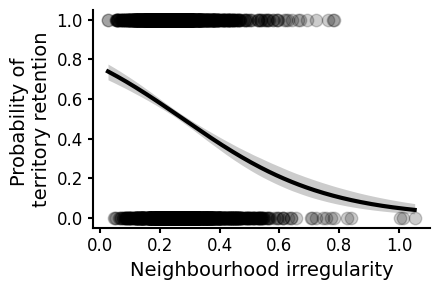

In [ ]:
fig,ax = plt.subplots(figsize=(4.5,3))

# Compute posterior P(reuse) distribution and back-transform to return to original units 
mu = fit['alpha'].reshape(-1,1) + fit['beta'].reshape(-1,1) * cv_grid[None,:]
y = scipy.special.expit(mu)
y_mean = np.mean(y, axis=0)
y_lower,y_upper = np.quantile(y, [0.025,0.975], axis=0)

# Plot model fits
ax.plot(cv_original, y_mean, linewidth=3, color='black')
ax.fill_between(cv_original, y_lower, y_upper, color='black', alpha=0.2, linewidth=0)

# Add scatter to the plot
ax.scatter(df['six_neighbour_cv'], df['persistent'], s=80, color='black', edgecolor='black', alpha=0.2, zorder=4)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)

ax.set_xlabel('Neighborhood irregularity', fontsize=14)
ax.set_ylabel('Probability of \nterritory retention', fontsize=14)

plt.tight_layout()
plt.savefig(out_dir/'mod_territory_retention.png', dpi=300, bbox_inches='tight')

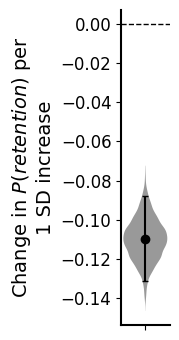

In [ ]:
fig, ax = plt.subplots(figsize=(2, 3.5))

# Compute posterior P(reuse) distribution and back-transform to return to original units 
retention_lower = scipy.special.expit(fit['alpha'].reshape(-1,1) + fit['beta'].reshape(-1,1) * -0.5)
retention_upper = scipy.special.expit(fit['alpha'].reshape(-1,1) + fit['beta'].reshape(-1,1) * 0.5)

p_retention = (retention_upper - retention_lower).reshape(-1)

## Violin plot
effects = [p_retention]
positions = [1]

parts = ax.violinplot(p_retention, positions=[1], widths=0.7, showmeans=False, showmedians=False, showextrema=False)
for pc in parts['bodies']:
    pc.set_facecolor('black')
    pc.set_edgecolor('none')
    pc.set_alpha(0.4)

## Compute medians + 95% intervals
med = np.median(p_retention)
low = np.quantile(p_retention, 0.025)
up = np.quantile(p_retention, 0.975)

## Overlay median + intervals
ax.errorbar(1, med, yerr=[[med-low], [up-med]], fmt='o', color='black', markersize=6, capsize=2, zorder=3)

ax.axhline(0, linestyle='--', color='black', linewidth=1)

ax.set_xticks(positions)
ax.set_xticklabels([])

ax.set_ylabel('Change in $P(retention)$ per \n1 SD increase', fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig(out_dir/'mod_causal_territory_retention.png', dpi=300, bbox_inches='tight')

In [35]:
print(low, med, up)

-0.13120845923605529 -0.10992835040396831 -0.08814849587608123
